In [26]:
#Submitted by:
#Noa Klein
#Shani Nadav

import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import levene as levene_test

custom_colors = ["#e19cb5", "#d5def6", "#c4e2ba", "#6d8fa3"]

In [27]:
# -------------------------------
# פונקציה: טווח אמון


In [28]:
# -------------------------------
def conf_band(values, level=0.95):
    avg = np.mean(values)
    stderr = st.sem(values)
    margin = stderr * st.t.ppf((1 + level) / 2., len(values) - 1)
    return avg, avg - margin, avg + margin


In [29]:
# -------------------------------
# פונקציה: מבחן Scheffé (חישוב ידני)


In [30]:
# -------------------------------
def scheffe_eval(summary):
    vals, groups = [], []
    for strat, arr in summary.items():
        vals.extend(arr)
        groups.extend([strat] * len(arr))

    df = pd.DataFrame({"value": vals, "group": groups})
    groups_list = df["group"].unique()
    k = len(groups_list)
    N = len(df)

    sse = sum(((df[df["group"] == g]["value"] - df[df["group"] == g]["value"].mean()) ** 2).sum()
              for g in groups_list)
    df_error = N - k
    mse = sse / df_error

    results = []
    for i in range(k):
        for j in range(i + 1, k):
            g1, g2 = groups_list[i], groups_list[j]
            x1, x2 = df[df["group"] == g1]["value"], df[df["group"] == g2]["value"]
            mean_diff = x1.mean() - x2.mean()
            n1, n2 = len(x1), len(x2)

            F_scheffe = (mean_diff ** 2) / (mse * (1 / n1 + 1 / n2)) / (k - 1)
            p_val = 1 - st.f.cdf(F_scheffe, k - 1, df_error)

            results.append((g1, g2, mean_diff, F_scheffe, p_val))

    res_df = pd.DataFrame(results, columns=["Group1", "Group2", "MeanDiff", "F_Scheffe", "p-value"])
    return res_df


In [31]:
# -------------------------------
# גרף: זמן עלייה ממוצע (Bar Plot)


In [32]:
# -------------------------------
def draw_mean_boarding(bdata):
    approaches = list(bdata.keys())
    avg_times = [np.mean(bdata[m]) for m in approaches]
    std_vals = [np.std(bdata[m]) for m in approaches]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(approaches, avg_times, yerr=std_vals, capsize=5,
                   color=custom_colors)

    for bar, val in zip(bars, avg_times):
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, yval + 10,
                 round(val, 2), ha='center', va='bottom')

    plt.xlabel('Boarding Strategy')
    plt.ylabel('Mean Boarding Duration (Minutes)')
    plt.title('Mean Boarding Duration by Strategy')
    plt.show()


In [33]:
# -------------------------------
# גרף: Histogram + KDE + CI


In [34]:
# -------------------------------
def show_hist_kde_ci(outcomes):
    strategies = list(outcomes.keys())
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for i, strat in enumerate(strategies):
        values = outcomes[strat]
        mean, low_ci, high_ci = conf_band(values)

        sns.histplot(values, kde=True, color=custom_colors[i],
                     ax=axes[i], bins=20, stat='probability')

        axes[i].axvline(low_ci, color='red', linestyle='--', label='95% CI')
        axes[i].axvline(high_ci, color='red', linestyle='--')

        axes[i].set_title(f"Method = {strat.capitalize()}")
        axes[i].set_xlabel("Boarding Duration (minutes)")
        axes[i].set_ylabel("Probability")

    plt.suptitle("Histograms, KDE curves and 95% Confidence Bands", y=1.02)
    plt.tight_layout()
    plt.show()


In [35]:
# -------------------------------
# גרף: Violin Plot


In [36]:
# -------------------------------
def show_violinplot(outcomes):
    plt.figure(figsize=(10, 6))
    vals, labels = [], []
    for strat, arr in outcomes.items():
        vals.extend(arr)
        labels.extend([strat] * len(arr))

    df = pd.DataFrame({
        'Boarding Duration (min)': vals,
        'Approach': labels
    })

    sns.violinplot(x='Boarding Duration (min)', y='Approach', hue='Approach',
                   data=df, palette=custom_colors, density_norm='width', legend=False)
    plt.title('Violin Plot of Boarding Durations by Approach')
    plt.show()


In [37]:
# -------------------------------
# גרף: Stacked Histogram


In [38]:
# -------------------------------
def show_stack_hist(outcomes):
    plt.figure(figsize=(10, 6))
    for (strat, arr), color in zip(outcomes.items(), custom_colors):
        sns.histplot(arr, kde=True, label=strat, bins=30, alpha=0.6, color=color)

    plt.xlabel('Boarding Duration (min)')
    plt.ylabel('Probability')
    plt.title('Distribution of Boarding Durations by Method')
    plt.legend(loc='upper right')
    plt.show()


In [39]:
# -------------------------------
# Boarding Method: Steffen Strategy


In [40]:
# -------------------------------
def steffen_strategy(passengers):
    windows = [p for p in passengers if p[1] in [1, 6]]
    middles = [p for p in passengers if p[1] in [2, 5]]
    aisles = [p for p in passengers if p[1] in [3, 4]]

    windows.sort(key=lambda x: -x[0])
    middles.sort(key=lambda x: -x[0])
    aisles.sort(key=lambda x: -x[0])

    return windows + middles + aisles


In [41]:
# -------------------------------
# סימולציה: תהליך עלייה


In [42]:
# -------------------------------
def simulate_boarding(n_people, n_rows, method):
    pax = [(row, seat) for row in range(1, n_rows + 1) for seat in range(1, 7)]
    done_times = [0] * n_people

    if method == 'random':
        np.random.shuffle(pax)
    elif method == 'FRONT TO BACK':
        ordered = []
        for r in range(1, n_rows + 1):
            seats = [(r, s) for s in range(1, 7)]
            np.random.shuffle(seats)
            ordered.extend(seats)
        pax = ordered
    elif method == 'BACK TO FRONT':
        ordered = []
        for r in range(n_rows, 0, -1):
            seats = [(r, s) for s in range(1, 7)]
            np.random.shuffle(seats)
            ordered.extend(seats)
        pax = ordered
    elif method == 'steffen':
        pax = steffen_strategy(pax)

    for idx in range(n_people):
        row, seat = pax[idx]
        bag_t = np.random.exponential(0.5)

        prev_block = 0
        tmp_take = 0

        for j in range(idx):
            prow, _ = pax[j]
            if prow <= row:
                prev_block = max(bag_t, done_times[j])
            else:
                prow2, _ = pax[j - 1]
                prow1, _ = pax[j]
                i, k = 1, 0
                while prow2 > prow1:
                    prow2, _ = pax[j - i]
                    prow1, _ = pax[j - k]
                    tmp_take = done_times[j - i]
                    i += 1
                    k += 1

        if seat <= 3:
            blockers = [done_times[i] for i, (r, s) in enumerate(pax[:idx])
                        if r == row and s > seat and s <= 3]
        else:
            blockers = [done_times[i] for i, (r, s) in enumerate(pax[:idx])
                        if r == row and s < seat and s > 3]

        if blockers:
            seat_t = np.random.exponential(0.5 + 0.25 * len(blockers))
        else:
            seat_t = 0

        total_t = max(tmp_take, prev_block) + bag_t + seat_t
        done_times[idx] = total_t

    return max(done_times)


In [43]:
# -------------------------------
# הרצה מרובה


In [44]:
# -------------------------------
def multi_runs(n_iter, n_people, n_rows):
    options = ['random', 'FRONT TO BACK', 'BACK TO FRONT', 'steffen']
    summary = {opt: [] for opt in options}
    for _ in range(n_iter):
        for opt in options:
            duration = simulate_boarding(n_people, n_rows, opt)
            summary[opt].append(duration)
    return summary


In [45]:
# -------------------------------
# ANOVA


In [46]:
# -------------------------------
def anova_eval(summary):
    arrs = [summary[m] for m in summary.keys()]
    f_val, p_val = st.f_oneway(*arrs)
    return f_val, p_val


In [47]:
# -------------------------------
# גרף: Cumulative Mean


In [48]:
# -------------------------------
def plot_cum_means(summary):
    plt.figure(figsize=(12, 6))
    for (opt, arr), color in zip(summary.items(), custom_colors):
        cum_means = np.cumsum(arr) / np.arange(1, len(arr) + 1)
        plt.plot(range(1, len(arr) + 1), cum_means, label=opt.capitalize(), color=color)
    plt.xlabel("Simulations")
    plt.ylabel("Cumulative Avg Boarding Time (min)")
    plt.title("Cumulative Averages by Strategy")
    plt.legend()
    plt.grid(True)
    plt.show()


In [49]:
# -------------------------------
# MAIN


Method: RANDOM
Mean Boarding Time: 94.08 minutes
Standard Deviation: 9.50 minutes
Variance: 90.16
Bias (compared to Steffen): 53.35 minutes
95% Confidence Interval: (92.18, 95.97) minutes
Minimum Time: 75.26 minutes
Maximum Time: 126.87 minutes
Method: FRONT TO BACK
Mean Boarding Time: 245.55 minutes
Standard Deviation: 13.50 minutes
Variance: 182.37
Bias (compared to Steffen): 204.83 minutes
95% Confidence Interval: (242.86, 248.25) minutes
Minimum Time: 211.10 minutes
Maximum Time: 278.20 minutes
Method: BACK TO FRONT
Mean Boarding Time: 103.19 minutes
Standard Deviation: 6.86 minutes
Variance: 47.06
Bias (compared to Steffen): 62.47 minutes
95% Confidence Interval: (101.82, 104.56) minutes
Minimum Time: 88.04 minutes
Maximum Time: 124.34 minutes
Method: STEFFEN
Mean Boarding Time: 40.72 minutes
Standard Deviation: 4.05 minutes
Variance: 16.38
Bias (compared to Steffen): 0.00 minutes
95% Confidence Interval: (39.92, 41.53) minutes
Minimum Time: 31.80 minutes
Maximum Time: 51.91 minut

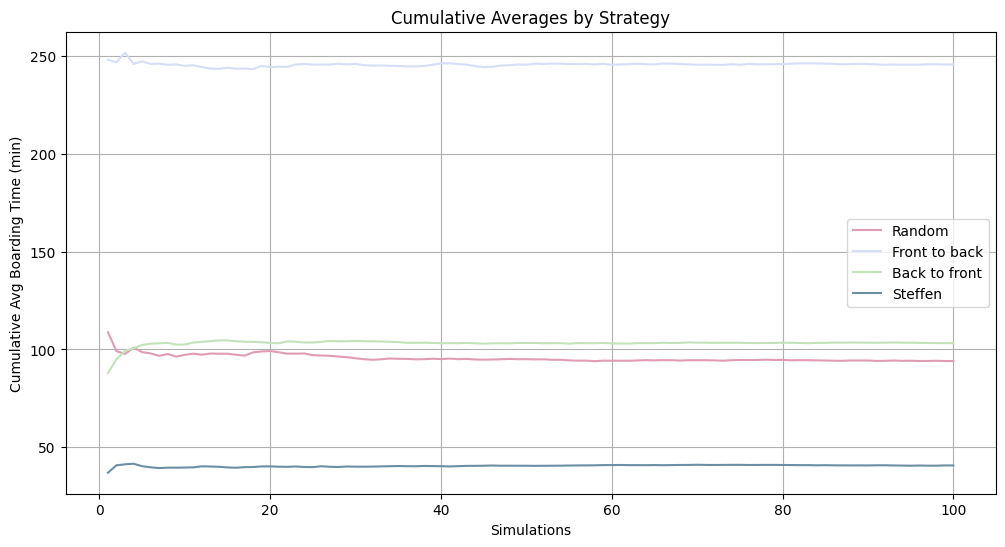

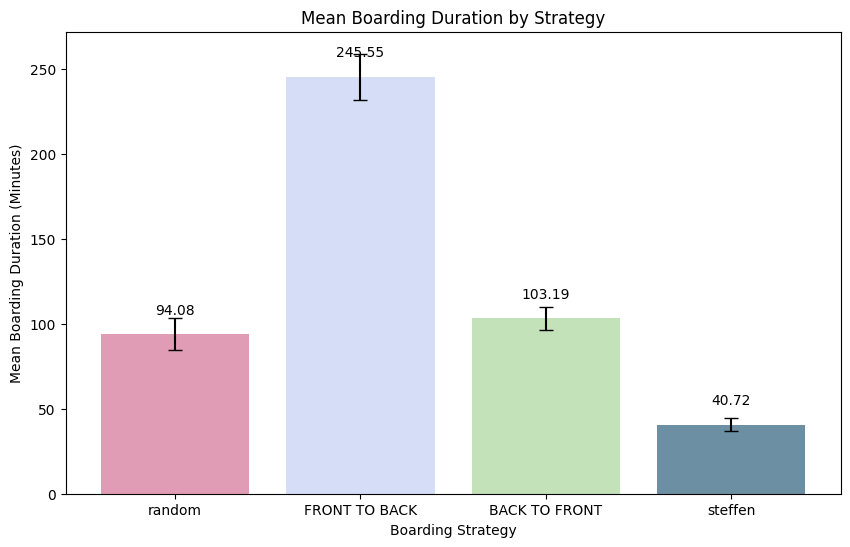

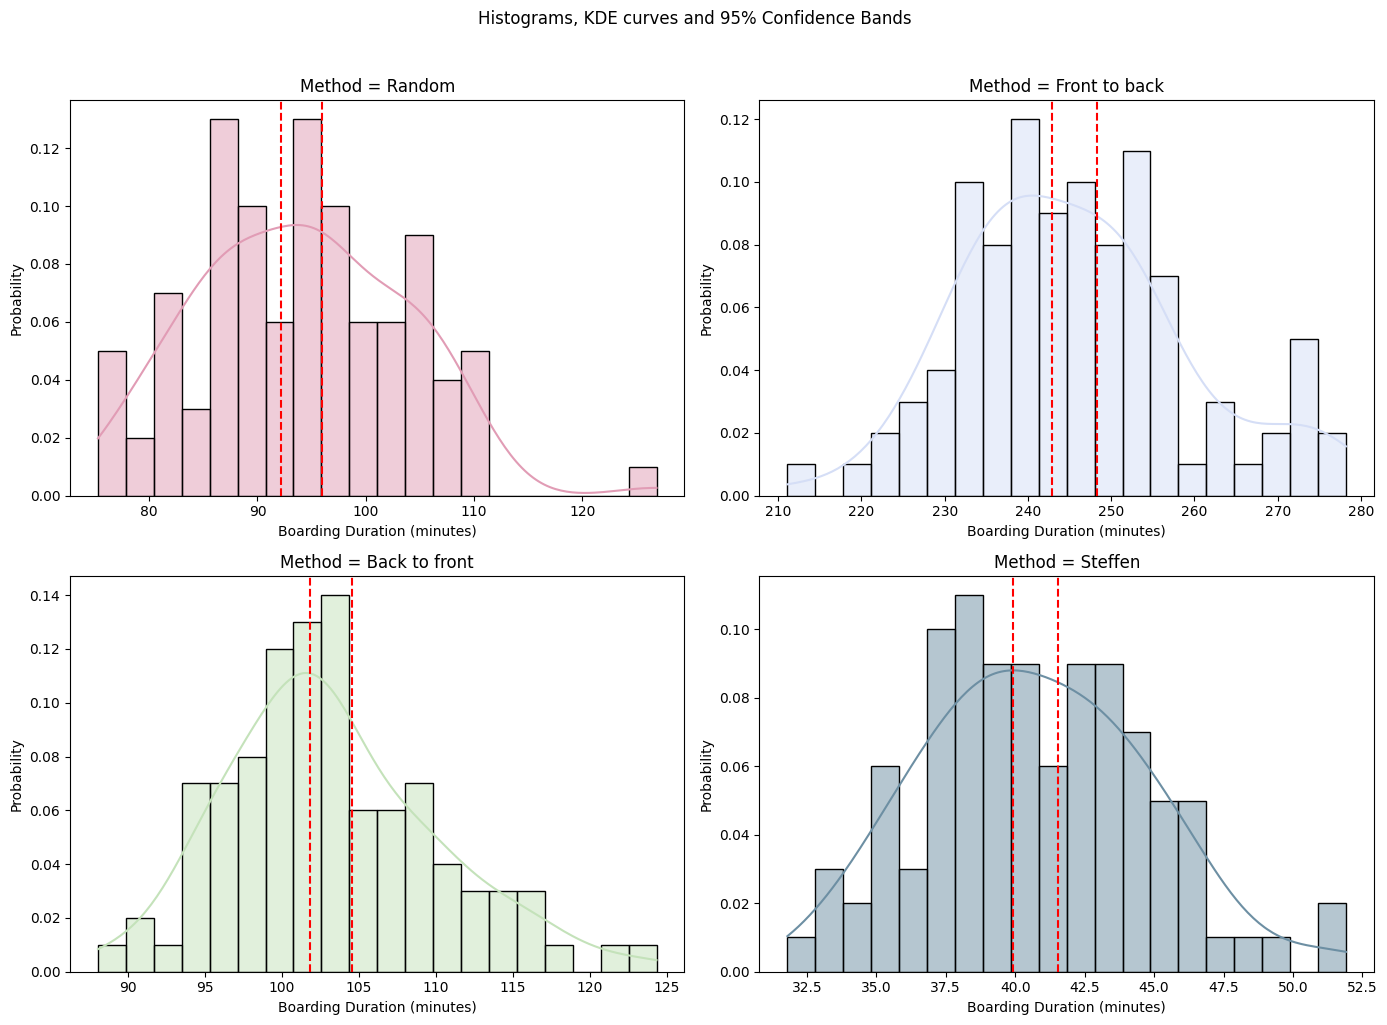

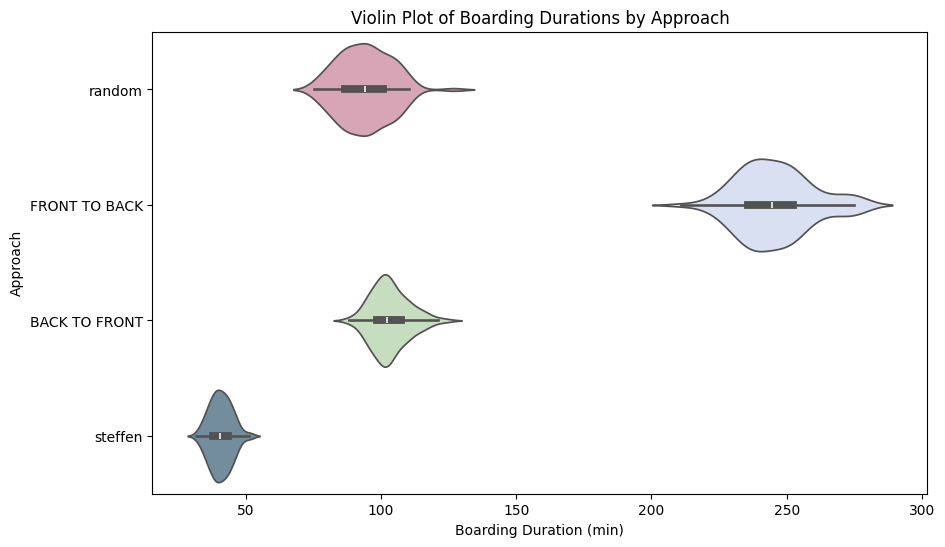

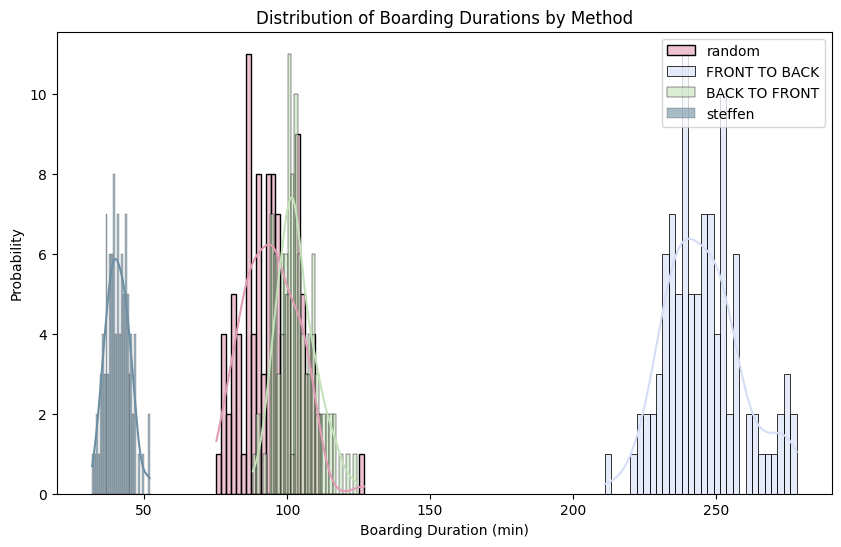

In [25]:
# -------------------------------
if __name__ == "__main__":
    n_iter = 100
    n_people = 300
    n_rows = 50

    results = multi_runs(n_iter, n_people, n_rows)

    for opt, arr in results.items():
        mean_val = np.mean(arr)
        std_val = np.std(arr)
        var_val = np.var(arr)
        bias_val = np.mean(arr) - np.mean(results['steffen'])
        mean_val, low, high = conf_band(arr)

        print(f"Method: {opt.upper()}")
        print(f"Mean Boarding Time: {mean_val:.2f} minutes")
        print(f"Standard Deviation: {std_val:.2f} minutes")
        print(f"Variance: {var_val:.2f}")
        print(f"Bias (compared to Steffen): {bias_val:.2f} minutes")
        print(f"95% Confidence Interval: ({low:.2f}, {high:.2f}) minutes")
        print(f"Minimum Time: {np.min(arr):.2f} minutes")
        print(f"Maximum Time: {np.max(arr):.2f} minutes")
        print("=" * 40)

    # ANOVA
    f_val, p_val = anova_eval(results)
    print(f"ANOVA test F-statistic: {f_val:.2f}")
    print(f"ANOVA test p-value: {p_val:.4f}")

    if p_val < 0.05:
        print("There is a statistically significant difference between the methods (p < 0.05).")
        print("\n=== Scheffé Post-Hoc Test ===")
        scheffe_table = scheffe_eval(results)
        print(scheffe_table.to_string(index=False))

        best_method = min(results, key=lambda m: np.mean(results[m]))
        print(f"\nThe best boarding method based on mean boarding time is: {best_method.capitalize()}")
    else:
        print("There is no statistically significant difference between the methods (p >= 0.05).")

    # Brown–Forsythe
    data = [results[m] for m in results]
    stat, p_val = levene_test(*data, center='median')
    print("\n=== Brown–Forsythe Test for Equality of Variances ===")
    print(f"Statistic = {stat:.2f}, p-value = {p_val:.4f}")
    if p_val < 0.05:
        print("Variances are significantly different between methods (p < 0.05).")
    else:
        print("Variances are not significantly different between methods (p >= 0.05).")

    # Plots
    plot_cum_means(results)
    draw_mean_boarding(results)
    show_hist_kde_ci(results)
    show_violinplot(results)
    show_stack_hist(results)
